In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "85bd815efd86af24338a0f0c45844cb7e1e6f155"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/85bd815efd86af24338a0f0c45844cb7e1e6f155/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Numerical Solvers

Anyone who has trained a network has seen a run blow up because the learning
rate was too large. It is tempting to blame the loss surface, with its sharp
valleys and its plateaus. Yet the same thing happens on the simplest loss
there is. Gradient descent on the bowl $\mathcal L(x)=25x^2$ takes the step
$x\leftarrow x-\eta\cdot 50x$, and for every learning rate above $\eta=0.04$
the iterates grow without bound, although the bowl has a single minimum and
nothing about it is difficult. If the loss is not the problem, what is?

The answer comes from an older subject. Gradient descent is a step-by-step
solution of the differential equation $\dot x=-50x$, which says: move downhill
at a speed proportional to the slope. This is the decay equation solved in
that section, fifty times faster, and its exact solution
$x(t)=e^{-50t}x_0$ decays to zero from every start. Euler proposed in 1768 to
solve such an equation by following the arrow for a short time $h$ and then
reading it again, and the learning rate plays the role of $h$. One step
multiplies $x$ by $1-50h$. With $h=0.01$ the factor is $0.5$, and the computed
solution decays like the true one. With $h=0.05$ it is $-1.5$, where the
exact factor is $e^{-2.5}=0.08$, and the computed solution flips sign and
grows. The equation is stable; the steps are not. In the previous section
the eigenvalues of an equation gave its exact motion. Here the same
eigenvalues decide how large a step can follow that motion.

Deep learning meets this gap between an equation and its steps wherever it
takes steps: in gradient descent (that section), in the layers of a
residual network (that section), and in the samplers of diffusion
and flow-matching models (that section). A sampler evaluates a network once or
twice in every step, so the number of steps sets the cost of an image.

Three questions decide what a step-by-step solution is worth. How far does
it stray from the true one? How can it stray less for the same work? And how
long may a step be before the errors grow instead of dying out? It turns out
that one object answers all three: the factor by which a step multiplies the
solution, which for Euler on the bowl was $1-50h$. At the end we return to
gradient descent and ask what a better solver would do for training.

In [1]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## Forward Euler

A trajectory is its start plus the velocity accumulated on the way. Over a
short step, Euler's proposal is the crudest one possible: pretend that the
velocity keeps the value it has at the start. Let us first see what this
does on an equation whose answer we know.

Take $\dot x=x$ from $x_0=1$ to $T=1$, where the answer is $e=2.718$. Divide
the interval into $n$ steps of length $h=1/n$, and in each step move with the
velocity at its start: $x\leftarrow x+hx=(1+1/n)x$. After $n$ steps,
$x_n=(1+1/n)^n$. This is a dollar at 100% annual interest compounded $n$
times a year:

| $n$ | 1 | 2 | 4 | 8 | 16 | 32 | 365 |
|---|---|---|---|---|---|---|---|
| $(1+1/n)^n$ | 2.000 | 2.250 | 2.441 | 2.566 | 2.638 | 2.677 | 2.7146 |
| error | 0.718 | 0.468 | 0.277 | 0.153 | 0.080 | 0.041 | 0.0037 |

The ratios of consecutive errors are $1.53,1.69,1.82,1.90,1.95$: doubling the
number of steps comes closer and closer to halving the error. Even daily
compounding falls more than a third of a cent short of $e$ dollars.

We have met this slow limit before. The compounding
$(\mathbf I+t\mathbf A/n)^n$ of that section was Euler's
method before it had a name: $n$ steps of length $t/n$ along a linear field.
The expansion found there,
$(1+\lambda t/n)^n\approx e^{\lambda t}\bigl(1-\tfrac{(\lambda t)^2}{2n}\bigr)$,
gives the dollar's error with $\lambda t=1$. It is about $e/(2n)=1.36\,h$.
Error proportional to $h$ is what we will call order one.

For a general field $\mathbf f(\mathbf x,t)$, with step size $h$ and grid
$t_n = nh$, where $n$ from here on counts the steps taken so far,
**forward Euler** is

$$
\mathbf{x}_{n+1} = \mathbf{x}_n + h\, \mathbf{f}(\mathbf{x}_n, t_n) .
$$

The method follows the arrow at the current point for time $h$, then reads the
field again. Equivalently, it is the Taylor expansion of the true solution cut
after the linear term, and the error of one step is the first term dropped. If
$\|\ddot{\mathbf{x}}(t)\| \le M$ along the solution, then

$$
\mathbf{x}(t_{n+1}) = \mathbf{x}(t_n) + h\,\mathbf{f}(\mathbf{x}(t_n), t_n) + \mathbf{r}_n,
\qquad
\|\mathbf{r}_n\| \le \tfrac{M h^2}{2}.
$$

The remainder $\mathbf r_n$ is the **local error**: what one step loses when
it starts on the true solution. What we want to know is the **global
error**, the distance from the true solution after all the steps to a fixed
horizon $T$. A local error of order $h^2$ does not give a global error of
order $h^2$. Reaching $T$ takes $T/h$ steps, their local errors accumulate,
and each step may amplify the error already made. One power of $h$ is lost.
The proof is short, and its structure matters more than its constant.

**Proposition (Euler converges at order 1).** *Let $\mathbf{f}$ be
$L$-Lipschitz in $\mathbf{x}$, that is
$\|\mathbf f(\mathbf x,t)-\mathbf f(\mathbf y,t)\|\le L\|\mathbf x-\mathbf y\|$
for all $\mathbf x$, $\mathbf y$ and $t$, and let the solution of
$\dot{\mathbf x}=\mathbf f(\mathbf x,t)$ from $\mathbf x(0)=\mathbf x_0$
satisfy $\|\ddot{\mathbf{x}}(t)\| \le M$ on $[0, T]$. Then the Euler iterates
the equation from the same start obey*

$$
\max_{n \le T/h} \|\mathbf{x}_n - \mathbf{x}(t_n)\|
\;\le\; \frac{M h}{2L}\left(e^{LT} - 1\right)
\;=\; O(h).
$$

**Proof.** Let $\varepsilon_n = \|\mathbf{x}_n - \mathbf{x}(t_n)\|$, and
subtract the Taylor identity above from the update
the equation:

$$
\varepsilon_{n+1}
\le \underbrace{\|\mathbf{x}_n - \mathbf{x}(t_n)\| + h\,\|\mathbf{f}(\mathbf{x}_n, t_n) - \mathbf{f}(\mathbf{x}(t_n), t_n)\|}_{\le\, (1 + hL)\, \varepsilon_n \textrm{ by Lipschitz}}
\;+\; \underbrace{\|\mathbf{r}_n\|}_{\le\, Mh^2/2} .
$$

Each step multiplies the existing error by at most $1 + hL$ and adds at most
$Mh^2/2$. Unrolling the recursion from $\varepsilon_0 = 0$ sums a geometric
series:

$$
\varepsilon_n \le \frac{Mh^2}{2} \sum_{j=0}^{n-1} (1 + hL)^j
= \frac{Mh^2}{2} \cdot \frac{(1 + hL)^n - 1}{hL}
\le \frac{Mh}{2L}\left(e^{LT} - 1\right),
$$

using $(1 + hL)^n \le e^{nhL} \le e^{LT}$. $\blacksquare$

For $\dot x=x$ on $[0,1]$ we have $M=\max|\ddot x|=e$ and $L=1$, so the bound
is $\tfrac e2(e-1)h=2.3\,h$, against the true error $1.36\,h$: the right
order, with a pessimistic constant. The structure of the bound recurs for
every solver. A local error of order $h^{p+1}$ per step becomes a global
error of order $h^p$ after $T/h$ steps, inflated by the factor $e^{LT}$ that
measures how strongly the dynamics amplify old mistakes. A method with global
error of order $h^p$ has **order** $p$; Euler has order $1$.

The factor $e^{LT}$ is the crude part. The constant $L$ records how steep the
field is and not which way it leans, so the bound cannot tell a field that
drives trajectories apart from one that pulls them together. For the bowl's
equation $\dot x=-50x$ on $[0,1]$ the factor is $e^{50}\approx5\times10^{21}$,
useless at any step a computer could take, although small steps follow the
decay well. A field that contracts needs an analysis of its own, and we come
to it after raising the order.

## Runge--Kutta Methods

Euler commits to the slope at the start of the step while the trajectory
curves away from it. Runge--Kutta methods measure the slope at points inside
the step and combine the measurements. the figure
shows one step of size $h=1$ on $\dot x=x$ from $x=1$.

![One step of size $h=1$ on $\dot x=x$ from $x=1$. (a) Euler follows the starting slope and lands at $2$. (b) The midpoint method takes a half step only to measure the slope there, $1.5$, and lands at $2.5$. (c) RK4 measures four slopes, $1$, $1.5$, $1.75$ and $2.75$, averages them with weights $\tfrac16(1,2,2,1)$ and lands at $2.708$; the exact value is $e=2.718$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-dyn-solver-geometry.svg)

### Midpoint, Heun and RK4

The simplest improvement, the **midpoint method**, takes half an Euler step
only to measure the slope there, and then takes the real step with that
slope. Writing $\mathbf f(\mathbf x)$ for a field that does not depend on
time, it is
$\mathbf{x}_{n+1} = \mathbf{x}_n + h\,\mathbf{f}\!\left(\mathbf{x}_n + \tfrac{h}{2}\mathbf{f}(\mathbf{x}_n)\right)$.
One Taylor line in one dimension shows why it helps:

$$
x + h f\!\left(x + \tfrac{h}{2} f(x)\right)
= x + h f + \tfrac{h^2}{2} f' f + O(h^3).
$$

The true expansion is $x(t+h) = x + h\dot{x} + \tfrac{h^2}{2}\ddot{x} + O(h^3)$
with $\ddot{x} = \tfrac{d}{dt} f(x(t)) = f' f$, so the $h^2$ term is now
right instead of missing. The local error is $O(h^3)$ and the global order
$2$, for two field evaluations per step.

The midpoint method spends its first evaluation on a half step. **Heun's
method** takes a full trial Euler step instead and averages the slopes at the
two ends of the step:

$$
\mathbf{x}_{n+1} = \mathbf{x}_n + \tfrac{h}{2}\Bigl[\mathbf{f}(\mathbf{x}_n) + \mathbf{f}\bigl(\mathbf{x}_n + h\,\mathbf{f}(\mathbf{x}_n)\bigr)\Bigr] .
$$

If the midpoint method is the midpoint rule for an integral, this is the
trapezoid rule. The same Taylor line gives it the same order $2$, at the same
two evaluations. Heun's method is the one to remember of the two, because
many diffusion samplers use it (that section).

Four slope measurements give the standard general-purpose method of
scientific computing, **classical Runge--Kutta (RK4)**, which goes back to
Kutta in 1901:

$$
\begin{aligned}
\mathbf{k}_1 &= \mathbf{f}(\mathbf{x}_n,\, t_n), \\
\mathbf{k}_2 &= \mathbf{f}(\mathbf{x}_n + \tfrac{h}{2}\mathbf{k}_1,\, t_n + \tfrac{h}{2}), \\
\mathbf{k}_3 &= \mathbf{f}(\mathbf{x}_n + \tfrac{h}{2}\mathbf{k}_2,\, t_n + \tfrac{h}{2}), \\
\mathbf{k}_4 &= \mathbf{f}(\mathbf{x}_n + h\,\mathbf{k}_3,\, t_n + h), \\
\mathbf{x}_{n+1} &= \mathbf{x}_n + \tfrac{h}{6}\left(\mathbf{k}_1 + 2\mathbf{k}_2 + 2\mathbf{k}_3 + \mathbf{k}_4\right).
\end{aligned}
$$

The update averages four slope measurements, weighting the two at the
midpoint twice. These are the weights of Simpson's rule,
$\int_a^b g \approx \tfrac{b-a}{6}\bigl(g(a) + 4g(\tfrac{a+b}{2}) + g(b)\bigr)$,
which integrates cubics exactly, with the midpoint's share split between two
measurements.

### The Stability Function

Why order $4$? On a linear field the answer takes one computation. Consider
the scalar equation $\dot y=\lambda y$, with $\lambda$ real or complex. It is
known as the *test equation*, and it stands for every linear field at once:
each mode of $\dot{\mathbf x}=\mathbf A\mathbf x$ obeys it, with $\lambda$ an
eigenvalue of $\mathbf A$ (that section). Its true solution
gains the factor $e^{h\lambda}$ over a time $h$. Each method multiplies $y$
by a fixed function of $z=h\lambda$ per step, and we can compare that
function with $e^z$.

**Proposition (stability functions).** *On the test equation, with
$z=h\lambda$, one step of each method multiplies $y$ by its **stability
function** $R(z)$:*

$$
R_{\textrm{Euler}}(z)=1+z,
\qquad
R_{\textrm{mid}}(z)=R_{\textrm{Heun}}(z)=1+z+\frac{z^2}{2},
\qquad
R_{\textrm{RK4}}(z)=1+z+\frac{z^2}{2}+\frac{z^3}{6}+\frac{z^4}{24}.
$$

**Proof.** For RK4 the four measurements are $k_1=\lambda y$,
$k_2=\lambda y(1+\tfrac z2)$,
$k_3=\lambda y(1+\tfrac z2+\tfrac{z^2}4)$ and
$k_4=\lambda y(1+z+\tfrac{z^2}2+\tfrac{z^3}4)$, each obtained by
substituting the previous one. The update is
$y+\tfrac z6\left(6+3z+z^2+\tfrac{z^3}4\right)y$, which is the stated
polynomial times $y$. For Euler, $y+zy$. For the midpoint method,
$y+h\lambda(y+\tfrac z2y)$, and for Heun, $y+\tfrac z2(y+(1+z)y)$; both are
$(1+z+\tfrac{z^2}2)y$. $\blacksquare$

Each $R$ is the Taylor polynomial of the exact factor $e^z$, cut at the
method's order. For RK4, $e^z-R_{\textrm{RK4}}(z)=z^5/120+O(z^6)$, so on this
equation one step errs by $O(h^5)$ and $T/h$ steps by $O(h^4)$. For nonlinear
fields that are four times continuously differentiable and Lipschitz in
$\mathbf x$, a longer Taylor match gives the same orders: midpoint and Heun
have order $2$, RK4 order $4$ [@Hairer.Norsett.Wanner.1993]. We do not
prove this; the expansion of four nested evaluations fills pages and teaches
little. The stability function is the object to keep from this section. How
closely it follows $e^z$ near $z=0$ is the accuracy of a method, and how
large it becomes far from zero will decide which steps are stable.

### Order at Equal Cost

It remains to measure the orders, and to compare the methods at the same
number of field evaluations. In code the two ends of the family take a few
lines each, for a field `f` that does not depend on time.

In [2]:
def euler(f, x0, T, n):
    """Forward Euler: n steps of size h = T/n."""
    x, h = np.asarray(x0, dtype=float), T / n
    for _ in range(n):
        x = x + h * f(x)
    return x

def rk4(f, x0, T, n):
    """Classical Runge-Kutta: four slope measurements per step."""
    x, h = np.asarray(x0, dtype=float), T / n
    for _ in range(n):
        k1 = f(x)
        k2 = f(x + 0.5 * h * k1)
        k3 = f(x + 0.5 * h * k2)
        k4 = f(x + h * k3)
        x = x + (h / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
    return x

On log--log axes, $\textrm{error} \approx C h^p$ is a line of slope $p$, so
the measured slopes should be $1$ and $4$. We test this on the spiral
$\dot{\mathbf x}=\mathbf A\mathbf x$ of the figure, whose
eigenvalues are $-0.5\pm\mathrm i$. A point on it loses length at rate
$\tfrac12$ while it turns at unit speed, so from $\mathbf x_0=(2,0)$ the exact
state at $T=2$ is $e^{-1}(2\cos 2,\,2\sin 2)=(-0.306,\,0.669)$, of length
$0.736$ (that section).

In [3]:
A = np.array([[-0.5, -1.0], [1.0, -0.5]])      # the spiral, eigenvalues -0.5 +- i
x0, T = np.array([2.0, 0.0]), 2.0
x_true = np.exp(-1) * np.array([2 * np.cos(2), 2 * np.sin(2)])  # e^{AT} x0

On a linear field we can predict the constants as well as the slopes. On
the spiral a step of either solver is a rotation combined with a rescaling,
as the exact motion is. A solver whose factor is off by some fraction in
each mode is therefore off by the same fraction of the length $0.736$ of the
true endpoint. For Euler the fraction is the one found for the compounding,
$|\lambda T|^2/(2n)$. Here $|\lambda T|^2=5$, so Euler should miss by $2.5/n$
of the length, that is by $1.84/n$.

For RK4 the fraction comes from the stability function. One step is off by
the fraction $|z|^5/120$, with $|z|=|\lambda T|/n=\sqrt5/n$, and the errors
of $n$ steps add. The sum is $5^{5/2}/(120\,n^4)$ of the length, or
$0.343/n^4$. The cell halves the step six times, from $8$ steps to $512$.

measured slope, Euler: 1.040
measured slope, RK4  : 4.022
error at 512 steps: Euler 3.6e-03, RK4 5.0e-12
RK4 with 128 steps (the same 512 evaluations): 1.3e-09


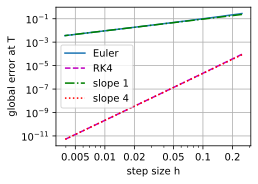

In [4]:
f = lambda x: A @ x                            # the spiral field
ns = 2 ** np.arange(3, 10)                     # 8, 16, ..., 512 steps
hs = T / ns
err_eu = np.array([np.linalg.norm(euler(f, x0, T, n) - x_true) for n in ns])
err_rk = np.array([np.linalg.norm(rk4(f, x0, T, n) - x_true) for n in ns])
print('measured slope, Euler:', f'{np.polyfit(np.log(hs), np.log(err_eu), 1)[0]:.3f}')
print('measured slope, RK4  :', f'{np.polyfit(np.log(hs), np.log(err_rk), 1)[0]:.3f}')
print(f'error at 512 steps: Euler {err_eu[-1]:.1e}, RK4 {err_rk[-1]:.1e}')
print('RK4 with 128 steps (the same 512 evaluations):',
      f'{np.linalg.norm(rk4(f, x0, T, 128) - x_true):.1e}')
d2l.plot(hs, [err_eu, err_rk, err_eu[-1] * (hs / hs[-1]),
              err_rk[-1] * (hs / hs[-1]) ** 4],
         'step size h', 'global error at T', xscale='log', yscale='log',
         legend=['Euler', 'RK4', 'slope 1', 'slope 4'])

The fitted slopes are $1.04$ and $4.02$, a little above $1$ and $4$ because
the fit includes steps as coarse as $h=0.25$, where the next terms of the
expansions still count. At $512$ steps the errors are $3.6\times10^{-3}$ and
$5.0\times10^{-12}$, which is what $1.84/n$ and $0.343/n^4$ predict. The
slopes hide the cost, though. RK4 reads the field four times per step, so a
fair comparison gives it a quarter of the steps. With the same $512$ field
evaluations, that is $128$ steps, RK4 reaches $1.3\times10^{-9}$, six orders
of magnitude below Euler. To match that, Euler's law $1.84/n$ asks for more
than a billion steps. In general a method of order $p$ needs a number of
steps proportional to $\varepsilon^{-1/p}$ for an error $\varepsilon$.

Practical solvers also choose the step size as they go. An *embedded pair*
such as Dormand--Prince computes solutions of orders $4$ and $5$ from the
same evaluations and takes their difference as an estimate of the local
error [@Dormand.Prince.1980]. The solver then shortens the step where
the estimate is large and lengthens it where the estimate is small. Exercise
1 builds the simplest such
controller.

## Stiffness and Implicit Methods

Order measures how accurate a step is when it is small. Stability asks a
different question: whether the errors of many steps die out or compound. For
Euler and RK4 the answer caps the step size, however little accuracy we need.

The smallest system that shows the problem has two decoupled modes,
$\dot{\mathbf x}=\mathrm{diag}(-50,-1)\,\mathbf x$ from $(1,1)$, followed to
$T=1$. By then the fast mode has decayed to $e^{-50}\approx10^{-22}$ and the
slow one stands at $e^{-1}=0.368$. After $t\approx0.1$ only the slow mode is
left, and steps of $h=0.1$ would follow it well. Yet the fast coordinate is
the opening's equation $\dot x=-50x$, and Euler multiplies it by $1-50h$ at
every step for as long as we integrate. A system is **stiff** when some
Jacobian eigenvalues have large negative real parts compared with the rate
at which the solution of interest varies: a mode that is long gone still
sets the step.

Which steps are allowed? The stability function answers. On the test
equation $\dot y=\lambda y$, whose solution decays if and only if
$\operatorname{Re}\lambda<0$, a method turns $y_0$ into $R(z)^ny_0$ after $n$
steps. The computed mode therefore decays if and only if $|R(z)|<1$. For
forward Euler this reads $|1+z|<1$, and for a real $\lambda<0$ it is
$-2<h\lambda<0$, or

$$
h < \frac{2}{|\lambda|} .
$$

For the bowl, $2/|\lambda|=2/50=0.04$ is the learning rate above which the
iterates of the opening grew.

Below the limit we also get what the error bound of Euler's method lacked,
an analysis for a field that contracts. A step now multiplies the error
already made by $|1+h\lambda|<1$, where the general proof could only bound
this factor by $1+hL$. For $h\le1/|\lambda|$ the geometric sum of that proof
stays below $1/(h|\lambda|)$, and the bound becomes $Mh/(2|\lambda|)$: the
old bound without its exponential. For the bowl's equation from $x_0=1$,
where $M=2500$, that is $25\,h$, within a factor of three of the true error.

### Backward Euler

A shorter step is one way out. The other looks odd at first: take Euler's
step with the slope at the *end* of the step,

$$
\mathbf{x}_{n+1} = \mathbf{x}_n + h\,\mathbf{f}(\mathbf{x}_{n+1}, t_{n+1}) .
$$

This is **backward Euler**. The unknown $\mathbf x_{n+1}$ stands on both
sides, a nuisance we postpone until we have seen what the method achieves.

**Proposition (backward Euler is stable at every step).** *On the test
equation with $\operatorname{Re}\lambda<0$, backward Euler has the stability
function $R(z)=1/(1-z)$, and $|R(z)|<1$ for every step $h>0$.*

**Proof.** One step is $y_{n+1}=y_n+h\lambda y_{n+1}$, so
$y_{n+1}=y_n/(1-z)$, and
$|1-z|\ge\operatorname{Re}(1-z)=1-\operatorname{Re}z>1$ when
$\operatorname{Re}z<0$. $\blacksquare$

The reason can be seen without the algebra. Forward Euler extrapolates with
the slope at the point where it stands, and on a steep mode that slope, held
for a long step, carries it far past zero. Backward Euler asks for the point
whose own slope leads back to where we are. A point that has almost decayed
has almost no slope, so no step is long enough to overshoot.

Now for the nuisance: the field is evaluated at a point that is not yet
known, so each step is an equation to solve, a linear system when the field
is linear and a few Newton iterations otherwise (Exercise
3). Such methods are called
*implicit*; Euler and RK4, which compute the new state by a formula, are
*explicit*. An implicit step is worth its solve when stability, not accuracy,
would set the step of an explicit method.

We now run both methods on the two-mode system at five step sizes, backward
Euler with one linear solve per step. The reader can predict the first row:
at $h=0.1$ forward Euler multiplies the fast coordinate by $1-5=-4$ ten
times.

In [5]:
def backward_euler_linear(A, x0, T, n):
    """Backward Euler on dx/dt = A x: solve (I - h A) x_new = x at each step."""
    x, h = np.asarray(x0, dtype=float), T / n
    for _ in range(n):
        x = np.linalg.solve(np.eye(len(x)) - h * A, x)
    return x

A_stiff = np.diag([-50.0, -1.0])               # one fast mode, one slow mode
x0_stiff = np.array([1.0, 1.0])
T = 1.0
print(f'exact at T = 1: fast {np.exp(-50):.1e}, slow {np.exp(-1):.4f}')
print(f'{"h":>5} {"fwd fast":>10} {"fwd slow":>9} {"bwd fast":>10} {"bwd slow":>9}')
for n in [10, 20, 25, 50, 100]:
    fwd = euler(lambda x: A_stiff @ x, x0_stiff, T, n)
    bwd = backward_euler_linear(A_stiff, x0_stiff, T, n)
    print(f'{T / n:5.2f} {fwd[0]:10.1e} {fwd[1]:9.4f} {bwd[0]:10.1e} {bwd[1]:9.4f}')

exact at T = 1: fast 1.9e-22, slow 0.3679
    h   fwd fast  fwd slow   bwd fast  bwd slow
 0.10    1.0e+06    0.3487    1.7e-08    0.3855
 0.05    3.3e+03    0.3585    1.3e-11    0.3769
 0.04   -1.0e+00    0.3604    1.2e-12    0.3751
 0.02    0.0e+00    0.3642    8.9e-16    0.3715
 0.01    7.9e-31    0.3660    2.5e-18    0.3697


At $h=0.1$ both methods have the slow mode within about $5\%$ of the truth
($0.349$ and $0.386$ against $0.368$), accurate enough for many purposes.
Forward Euler nonetheless returns $4^{10}\approx10^6$ for the fast component,
whose true value is $10^{-22}$. At $h=0.05$ its factor is the opening's
$-1.5$, applied twenty times. At $h=0.04$ the factor is $-1$, and the fast
component flips sign at every step and never shrinks. (The zero in the row
$h=0.02$ is exact: there $1-50h=0$, and one step removes the fast mode.)
Forward Euler needs $h<0.04$, a step at which its slow mode is already within
about $2\%$. We asked for $5\%$, and stability made us compute $2\%$.

Backward Euler is stable at every step size. Its slow-mode error is the
$O(h)$ error of a first-order method, so stability does not bring accuracy.

### Stability Regions

Forward Euler has a step-size limit and backward Euler has none. Where do
other methods stand? A plot of the $z$ plane shows all of them at once. The
**stability region** of a method is the set $\{z:|R(z)|<1\}$ where its update
decays. A method is **A-stable** if its region contains the whole open left
half-plane $\operatorname{Re}z<0$: it makes every decaying mode decay,
whatever the step [@Dahlquist.1963]. Backward Euler is A-stable, since
its region is everything outside the closed unit disc around $+1$.

the figure marks the examples. The opening's
step $h=0.05$ on $\dot x=-50x$ is the point $z=-2.5$, outside Euler's disc,
and $h=0.01$ is $z=-0.5$, inside. The spiral, with $\lambda=-0.5\pm\mathrm i$,
gives $|1+z|^2=(1-h/2)^2+h^2$, which is below $1$ if and only if $h<0.8$; at
$h=0.8$ its two points $-0.4\pm0.8\,\mathrm i$ lie on the circle. A pure
rotation puts $z$ on the imaginary axis, which touches Euler's disc only at
the origin, so forward Euler makes an undamped oscillation grow at every
step size (Exercises 2 and
4). The exact step $e^{z}$ of
that section has modulus below one on the whole
left half-plane, which is the behaviour backward Euler imitates and forward
Euler does not.

![Stability regions in the complex plane of $z = h\lambda$ for the test equation $\dot{y} = \lambda y$; a decaying mode sits in the left half-plane. Forward Euler decays only inside the disc $\lvert 1 + z \rvert < 1$, whose real slice is $-2 < h\lambda < 0$; RK4 enlarges it to a lobed region reaching $\approx -2.79$ on the real axis; backward Euler is stable everywhere except the disc around $+1$, in particular on the entire left half-plane, which is A-stability. The marked points are the opening's $h=0.05$ step, its $h=0.01$ step, and the spiral at $h=0.8$, on the edge of Euler's disc.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-dyn-stability-regions.svg)

No explicit Runge--Kutta method is A-stable, however many stages it has. Its
$R$ is a polynomial (Exercise 2),
and a polynomial other than a constant grows without bound as $z$ runs out
along the negative real axis. Higher order therefore does not cure
stiffness. RK4's region ends on the real axis at $z=-2.79$, the negative
root of $R_{\textrm{RK4}}(z)=1$. On the bowl's equation it allows
$h<2.79/50=0.056$ where Euler allows $0.04$, and it reads the field four
times per step. This is why implicit methods are kept for stiff fields,
while explicit ones are the default everywhere else. The stiff field that
readers of this book meet most often is the gradient of a loss whose
curvature is large in some directions and small in others.

## Gradient Descent as a Solver

The opening treated one coordinate. With several, the same factor appears
once per eigenvalue of the Hessian. Moving downhill continuously on a loss
$\mathcal L$, always along the negative gradient, is the **gradient flow**

$$
\dot{\mathbf{x}} = -\nabla \mathcal L(\mathbf{x}),
$$

a field that vanishes at the critical points of $\mathcal L$ and along
whose trajectories the loss only falls:
$\tfrac{d}{dt}\mathcal L(\mathbf{x}(t)) = \nabla \mathcal L^\top \dot{\mathbf{x}} = -\|\nabla \mathcal L\|^2 \le 0$.
Gradient descent with learning rate $\eta$,
$\mathbf{x}_{k+1} = \mathbf{x}_k - \eta\, \nabla \mathcal L(\mathbf{x}_k)$,
is forward Euler the equation on this flow with $h = \eta$.

that section derives the learning-rate
ceiling $\eta<2/\lambda_{\max}(\mathbf H)$ on a quadratic with Hessian
$\mathbf H$ and studies the speed below it. We do not repeat the study of
the speed. The ceiling we derive once more, in three arrows, because the
route is what the solver view adds. Write
$\boldsymbol\delta=\mathbf x-\mathbf x^\star$ for the displacement from a
minimum $\mathbf x^\star$ with Hessian $\mathbf H$. Near the minimum the flow
linearizes, and each eigenvalue $\lambda_i$ of $\mathbf H$ becomes a
decaying mode with rate $-\lambda_i$, a copy of the test equation:

$$
\begin{aligned}
\dot{\mathbf{x}} = -\nabla \mathcal L(\mathbf{x})
\;\;&\xrightarrow{\textrm{linearize}}\;\;
\dot{\boldsymbol{\delta}} = -\mathbf H\boldsymbol{\delta}
\;\;\xrightarrow{\textrm{Euler}, \, h = \eta}\;\;
\boldsymbol{\delta}_{k+1} = (\mathbf I - \eta \mathbf H)\,\boldsymbol{\delta}_k \\
&\xrightarrow{\textrm{stability}}\;\;
\eta < \frac{2}{\lambda_{\max}(\mathbf H)} .
\end{aligned}
$$

The learning-rate ceiling is thus the boundary of Euler's stability disc,
reached by the steepest mode at $z=-\eta\lambda_{\max}=-2$.

If this reading is right, the ceiling comes from Euler's method, and another
solver must have another ceiling. Let us test this prediction on the valley
on which that section sweeps the learning
rate, $\mathcal L(\mathbf x)=\tfrac12\mathbf x^\top\mathbf H\mathbf x$ with
$\mathbf H=\mathrm{diag}(10,1)$ (that section lists the flat coordinate
first). Its gradient flow $\dot{\mathbf x}=-\mathbf H\mathbf x$ has a steep
mode with rate $-10$ and a flat one with rate $-1$. From $(1,1)$ we take
$100$ steps of size $\eta$ with three solvers. Forward Euler is gradient descent, with its ceiling at
$2/10=0.2$. RK4 reads the gradient four times per step, and since its region
reaches $-2.79$ on the real axis (the figure),
its ceiling should be $0.279$. Backward Euler,
$\mathbf x_{k+1}=(\mathbf I+\eta\mathbf H)^{-1}\mathbf x_k$, should have none.
For each run the cell prints the factors by which one step multiplies the two
modes, $R(-10\eta)$ and $R(-\eta)$, and the length of the iterate after the
$100$ steps. The factors are measured, by applying one step to the identity
matrix.

In [6]:
H = np.diag([10.0, 1.0])                       # Hessian of L(x) = x^T H x / 2
flow = lambda x: -H @ x                        # the gradient flow
solvers = {                                    # n steps of size eta on the flow
    'forward Euler': lambda x0, eta, n: euler(flow, x0, n * eta, n),
    'RK4': lambda x0, eta, n: rk4(flow, x0, n * eta, n),
    'backward Euler': lambda x0, eta, n: backward_euler_linear(-H, x0, n * eta, n)}
print(f'{"solver":<15}{"eta":>6}{"steep factor":>14}{"flat factor":>13}{"||x_100||":>12}')
for name, eta in [('forward Euler', 0.19), ('forward Euler', 0.21), ('RK4', 0.27),
                  ('RK4', 0.29), ('backward Euler', 0.25), ('backward Euler', 25)]:
    steep, flat = np.diag(solvers[name](np.eye(2), eta, 1))  # one step's matrix
    x_100 = solvers[name](np.array([1.0, 1.0]), eta, 100)
    print(f'{name:<15}{eta:6.2f}{steep:14.3f}{flat:13.3f}{np.linalg.norm(x_100):12.1e}')

solver            eta  steep factor  flat factor   ||x_100||
forward Euler    0.19        -0.900        0.810     2.7e-05
forward Euler    0.21        -1.100        0.790     1.4e+04
RK4              0.27         0.879        0.763     2.5e-06
RK4              0.29         1.187        0.748     2.8e+07
backward Euler   0.25         0.286        0.800     2.0e-10
backward Euler  25.00         0.004        0.038    3.2e-142


Each solver has its own ceiling, where its stability region ends. Forward
Euler converges at $\eta=0.19$, with a steep factor of $-0.9$, and diverges
at $\eta=0.21$, with $-1.1$. RK4 still converges at $\eta=0.27$ and diverges
at $0.29$. Backward Euler converges at $\eta=0.25$, above the ceiling of
gradient descent, and at $\eta=25$, far above both, where its factors are
$0.004$ and $0.038$ and a hundred steps leave nothing measurable of the
iterate. The opening asked what the problem is, if it is not the loss. The
answer is that the ceiling is a quotient. The loss supplies its denominator,
$\lambda_{\max}$, and the solver supplies its numerator, which is $2$ for
forward Euler and $2.79$ for RK4. Backward Euler has no ceiling at all.

Should we then train with RK4? No. Its ceiling is $1.4$ times higher and its
step takes four gradients, so each gradient advances the flow by at most
$0.07$, against $0.2$ for gradient descent. The extra gradients serve to
follow the path of the gradient flow more closely, and an optimizer has no
use for the path. It wants the place where the path ends. Nor is leaving the
path only an error. To second order in $\eta$ the iterates of gradient
descent follow the flow of a modified loss that penalizes large gradients,
so the error that Euler makes as a solver acts as a regularizer (Exercise
5).

The two methods also fail differently. Euler's steep factor leaves the
stable range through $-1$, and the iterate jumps across the valley floor to
land higher each time. RK4's factor is positive on the whole real axis and
leaves through $+1$: at $\eta=0.29$ it is $1.187$, and the iterate walks
away from the minimum without once changing sign. The zigzag, too, belongs
to Euler's method. Momentum, the usual remedy for it, solves a different
equation: Polyak's heavy ball discretizes
$m\ddot{\mathbf x}+c\dot{\mathbf x}=-\nabla\mathcal L(\mathbf x)$, the motion
of a ball with mass and friction [@Polyak.1964] (Exercise
6).

Backward Euler only improves as the step grows, since its factors
$1/(1+\eta\lambda_i)$ shrink. The catch is the solve. Its step
$\mathbf x_{k+1}=\mathbf x_k-\eta\nabla\mathcal L(\mathbf x_{k+1})$ says that
the gradient of
$\mathcal L(\mathbf x)+\tfrac1{2\eta}\|\mathbf x-\mathbf x_k\|^2$ vanishes at
$\mathbf x_{k+1}$, which for a convex loss makes it the proximal step
$\mathrm{prox}_{\eta\mathcal L}(\mathbf x_k)$ of
that section, applied to the loss itself. On our
quadratic that is one linear system. On a network it is an optimization
problem of its own at every step, and for large $\eta$ it is the problem we
set out to solve.

The valley is the stiff system of that section in a
milder form, with rates $10$ and $1$ in place of $50$ and $1$, and $\eta$ in
place of $h$. At any $\eta<0.2$ the flat factor $1-\eta$ of gradient descent
stays above $0.8$ (the table prints $0.81$ at $\eta=0.19$), so the flat
direction loses less than a fifth of its length per step, however well the
steep one does. In general it loses less than the fraction
$2\lambda_{\min}/\lambda_{\max}$, which is a five-hundredth for a condition
number of $1000$. Stability fixes $\eta$ through $\lambda_{\max}$, and
$\lambda_{\min}$ then sets the speed, so the condition number of the Hessian
is the stiffness of the gradient flow. A diverging learning rate is a solver
instability.

We knew the eigenvalues of every field in this section before we took the
first step, because we had written the field down ourselves. A field that is
a network comes with no such list. that section takes a
learned field as the model itself, with layers for Euler steps, and asks how
such a model is trained and what it does to a probability density.

## Summary

A numerical solver replaces a trajectory by steps, and two properties judge
it. Its order $p$ says how fast the error falls with the step: a local error
$O(h^{p+1})$ accumulates to a global error $O(h^p)$, with $p=1$ for Euler and
$p=4$ for RK4. Its stability region says which steps do not blow up: forward
Euler needs $|1+h\lambda|<1$, backward Euler is stable on the whole left
half-plane and solves an equation at every step, and a system is stiff when
a fast mode that has long decayed still sets the step. On a linear field
both properties are read from the stability function $R(h\lambda)$, the
factor by which one step multiplies a mode. Gradient descent is forward
Euler on $\dot{\mathbf x}=-\nabla\mathcal L$, so its ceiling
$\eta<2/\lambda_{\max}(\mathbf H)$ is the edge of Euler's region, and
ill-conditioning is stiffness.

## Exercises

1. [code] **Adaptive step size.** ● An embedded pair estimates the local
   error from two methods of different order. The simplest pair uses the
   stages $\mathbf{k}_1 = \mathbf{f}(\mathbf{x})$ and
   $\mathbf{k}_2 = \mathbf{f}(\mathbf{x} + h\mathbf{k}_1)$ of Heun's method:
   the Euler value $\mathbf{x} + h\mathbf{k}_1$ and the Heun value
   $\mathbf{x} + \tfrac{h}{2}(\mathbf{k}_1 + \mathbf{k}_2)$ differ by
   $\Delta = \tfrac{h}{2}\|\mathbf{k}_2 - \mathbf{k}_1\|$. A controller
   accepts the step, keeping the Heun value, when $\Delta \le \texttt{tol}$,
   and in either case continues with the step size

   $$
   h \leftarrow h \min\!\Big(2,\ \max\!\big(0.2,\ 0.9\sqrt{\texttt{tol}/\Delta}\,\big)\Big).
   $$

    1. Which order of the local error does the exponent $1/2$ assume?
    1. Implement the controller, starting from $h = 0.1$ and shortening the
       last step so that it ends at $T$. Integrate the spiral field `f` from
       `x0` to $T = 2$ for $\texttt{tol} = 10^{-2}, 10^{-3}, \ldots, 10^{-6}$.
       Count the field evaluations, including those of rejected steps, and
       compare the error with the exact endpoint `x_true`. How does the
       number of evaluations scale with $\texttt{tol}$?
    1. Integrate the field of `A_stiff` from $(1, 1)$ to $T = 10$ with
       $\texttt{tol} = 10^{-3}$ and plot the accepted step sizes against
       time. At which value do they settle after the fast mode has decayed?
       Explain this value with Heun's stability function
       $1 + z + z^2/2$ from the equation.

1. **Rotating modes.** ● The stiff example has real eigenvalues. A complex
   eigenvalue $\lambda$ enters through $z = h\lambda$, the coordinate of
   the figure, and its imaginary part can decide
   whether a step is stable.
    1. For the spiral field of the figure, with
       eigenvalues $-0.5 \pm \mathrm i$, the text found that forward Euler
       decays for $h < 0.8$. Find the largest such step for Heun's method
       from its stability function in the equation
       (the condition is a cubic in $h$; solve it numerically), and for RK4.
       Heun's method reads the field twice per step and RK4 four times.
       Which of the three methods covers the most time per field evaluation
       without growing?
    1. For the rotational field
       $\dot{\mathbf{x}} = \left(\begin{smallmatrix}0&-b\\b&0\end{smallmatrix}\right)\mathbf{x}$,
       show that forward Euler multiplies $\|\mathbf{x}\|$ by
       $\sqrt{1 + h^2 b^2}$ per step and that backward Euler divides it by the
       same factor. By which factor does each method change $\|\mathbf{x}\|$
       over one revolution, that is $2\pi/(hb)$ steps, when $hb = 0.1$?
    1. The stability function of RK4 is the last formula in
       the equation, and its square modulus on the
       imaginary axis decides rotation. Show that
       $|R(\mathrm iy)|^2 = 1 - y^6/72 + y^8/576$ for real $y$, and find the
       range of $hb$ for which RK4 does not amplify the rotation.
    1. An explicit Runge--Kutta method with $s$ stages computes
       $\mathbf{k}_i = \mathbf{f}\big(\mathbf{x}_n + h\sum_{j<i} a_{ij}\mathbf{k}_j\big)$
       for $i = 1, \ldots, s$ and
       $\mathbf{x}_{n+1} = \mathbf{x}_n + h\sum_{i} b_i\mathbf{k}_i$, as RK4
       does in the equation. Show that its stability
       function is a polynomial in $z$ of degree at most $s$. Why does this
       rule out A-stability for explicit methods?

1. [code] **Implicit steps on a stiff nonlinear field.** ● The text's stiff
   system is linear and diagonal, so each backward-Euler step was one linear
   solve. Take instead the damped pendulum
   $\dot\phi=\omega$, $\dot\omega=-\sin\phi-c\,\omega$ of
   that section with the heavy damping $c=50$, from
   $(\phi,\omega)=(1,0)$ to $T=2$.
    1. Compute the eigenvalues of its Jacobian
       $\mathbf J(\phi,\omega)=\left(\begin{smallmatrix}0&1\\-\cos\phi&-c\end{smallmatrix}\right)$
       at the bottom, $(0,0)$, and the step-size limits of forward Euler and
       RK4 that they imply.
    1. Show that after the fast transient the motion nearly satisfies
       $\dot\phi=-\sin\phi/c$, and compute $\phi(2)$ from this
       one-dimensional equation.
    1. One backward-Euler step solves
       $\mathbf g(\mathbf y)=\mathbf y-\mathbf x_n-h\mathbf f(\mathbf y)=\mathbf 0$
       for $\mathbf y=\mathbf x_{n+1}$. Write Newton's iteration
       $\mathbf y\leftarrow\mathbf y-(\mathbf I-h\mathbf J(\mathbf y))^{-1}\mathbf g(\mathbf y)$
       for it, and implement backward Euler with three Newton iterations per
       step, started from $\mathbf x_n$.
    1. Run forward Euler, RK4 and backward Euler with $n=20$, $33$, $36$ and
       $100$ equal steps ($h=0.1$, $0.061$, $0.056$ and $0.02$), against a
       reference computed with `rk4` and $2^{16}$ steps. Which runs blow up,
       and do the limits of part a predict them? Then find for each method
       the smallest $n$ with an endpoint error below $10^{-4}$, and count
       the field and Jacobian evaluations it takes. For which method does
       accuracy set $n$, and for which does stability?

1. [code] **Symplectic Euler and splitting.** ● The harmonic oscillator
   $\dot q=p$, $\dot p=-q$ conserves $q^2+p^2$. Forward Euler spirals out of
   its circular orbits and backward Euler spirals in. The *symplectic Euler*
   update advances $q$ with the old $p$ and then $p$ with the new $q$:
   $q_{n+1}=q_n+hp_n$, $p_{n+1}=p_n-hq_{n+1}$.
    1. Write the update as a matrix $\mathbf S_h$ acting on $(q,p)$ and show
       that $\det\mathbf S_h=1$ for every $h$, so the update preserves area as
       the exact flow does, while forward Euler's matrix has determinant
       $1+h^2$.
    1. Show that the eigenvalues of $\mathbf S_h$ are distinct and lie on the
       unit circle if and only if $0<h<2$. What happens at $h=2$ and for
       $h>2$?
    1. Show that $q^2+p^2+hqp$ is conserved exactly by the update. What does
       its level set through $(1,0)$ look like, and how far from the origin
       can the computed orbit get at $h=0.5$ and at $h=1$? (Hint: the axes of
       the quadratic form have lengths in the ratio
       $\sqrt{(2+h)/(2-h)}$.)
    1. Integrate from $(1,0)$ to $T=200$ with forward Euler, backward Euler
       and symplectic Euler at $h=0.1$ and $h=1$, and report the largest and
       smallest $\|(q,p)\|$ along each run.
    1. The update is the exact flow of $\dot q=p$ with $p$ frozen, for time
       $h$, followed by the exact flow of $\dot p=-q$ with $q$ frozen. Write
       the two generators $\mathbf P$ and $\mathbf Q$, whose sum is the
       oscillator's matrix, compute $e^{h\mathbf P}$, $e^{h\mathbf Q}$ and
       $e^{h(\mathbf P+\mathbf Q)}$, and show that
       $e^{h\mathbf Q}e^{h\mathbf P}=\mathbf S_h$ differs from
       $e^{h(\mathbf P+\mathbf Q)}$ by terms of order $h^2$. The spiral's
       closed form in that section split an exponential
       without any error. Which property that it used fails here? The
       symmetric splitting
       $e^{h\mathbf Q/2}e^{h\mathbf P}e^{h\mathbf Q/2}$ is the *leapfrog*
       integrator of Hamiltonian Monte Carlo [@Neal.2011]; what is its
       order?

1. [code] **Implicit gradient regularization.** ●● Gradient descent is
   forward Euler on the gradient flow (that section), so
   each step leaves the flow of $\mathcal L$ by $O(\eta^2)$. Backward error
   analysis looks for a modified field
   $\tilde{\mathbf{f}} = \mathbf{f} + \eta\mathbf{f}_1$ whose exact
   time-$\eta$ flow agrees with one Euler step up to $O(\eta^3)$.
   @Barrett.Dherin.2021 find that for gradient descent this field is
   again a gradient field, of the modified loss

   $$
   \tilde{\mathcal L}(\mathbf{x}) = \mathcal L(\mathbf{x}) + \frac{\eta}{4}\|\nabla \mathcal L(\mathbf{x})\|^2 .
   $$

    1. Expand the exact flow of $\tilde{\mathbf{f}}$ over time $\eta$ to
       second order, and show that
       $\mathbf{f}_1 = -\tfrac12(\partial\mathbf{f}/\partial\mathbf{x})\,\mathbf{f}$.
       Derive $\tilde{\mathcal L}$ for $\mathbf{f} = -\nabla \mathcal L$.
       Which regions of parameter space does the added term penalize?
    1. For $\mathcal L(x) = \tfrac{\lambda}{2}x^2$ with $0 < \eta\lambda < 1$,
       show that the iterates of gradient descent lie exactly on the gradient
       flow of $\tfrac{\tilde{\lambda}}{2}x^2$ with
       $\tilde{\lambda} = -\log(1 - \eta\lambda)/\eta$. Expand
       $\tilde{\lambda}$ in $\eta$ and compare it with the curvature of
       $\tilde{\mathcal L}$.
    1. Gradient descent on this quadratic still converges for
       $1 < \eta\lambda < 2$, with iterates that alternate in sign.
       Trajectories of a scalar autonomous field with a Lipschitz constant
       cannot cross, so the time-$\eta$ map of such a field preserves order.
       Conclude that no such field takes the values of the iterates at the
       times $k\eta$. For a quadratic with Hessian $\mathbf H$ in $d$
       dimensions, show that for every starting point with a component along
       the top eigenvector, the iterates lie on the flow of no gradient field
       $-\nabla\big(\tfrac12\mathbf{x}^\top\tilde{\mathbf H}\mathbf{x}\big)$
       once $\eta \ge 1/\lambda_{\max}(\mathbf H)$.
    1. For $\mathcal L(x) = x^4/4 + x^2/2$ and $x_0 = 1.5$, run gradient
       descent to $T = 1$ with $\eta = 0.1, 0.05, 0.025, 0.0125$. Compute the
       gradient flows of $\mathcal L$ and of $\tilde{\mathcal L}$ to $T = 1$
       with `rk4` and many steps, the latter separately for each $\eta$. Fit
       the slopes of the two endpoint errors of gradient descent against
       $\eta$.

1. **Heavy ball as a discretized ODE.** ● Heavy-ball momentum
   $\mathbf{x}_{k+1} = \mathbf{x}_k - \eta\nabla \mathcal L(\mathbf{x}_k) + \beta(\mathbf{x}_k - \mathbf{x}_{k-1})$
   discretizes the equation
   $m\ddot{\mathbf{x}} + c\dot{\mathbf{x}} = -\nabla \mathcal L(\mathbf{x})$
   of a ball with mass $m$ and friction $c$.
    1. Replace $\ddot{\mathbf{x}}(t_k)$ by the central difference
       $(\mathbf{x}_{k+1} - 2\mathbf{x}_k + \mathbf{x}_{k-1})/h^2$ and
       $\dot{\mathbf{x}}(t_k)$ by the backward difference
       $(\mathbf{x}_k - \mathbf{x}_{k-1})/h$. Show that the result is the
       heavy-ball update, and express $\eta$ and $\beta$ through $m$, $c$,
       and $h$.
    1. For $\mathcal L(x) = \tfrac{\lambda}{2}x^2$ the ODE is a damped
       oscillator, critically damped at $c = 2\sqrt{m\lambda}$. Express this
       condition through $\eta$, $\beta$, and $\lambda$. The heavy-ball
       recurrence is critically damped when its characteristic polynomial
       $z^2 - (1 + \beta - \eta\lambda)z + \beta$ has a double root. Find the
       corresponding $\beta$ and compare the two conditions for small
       $\eta\lambda$.
    1. The heavy-ball recurrence on this quadratic converges if and only if
       $0 < \eta\lambda < 2(1 + \beta)$ for $0 \le \beta < 1$ (Exercise
       7a
       of that section asks for the proof).
       Translate the condition into one on $h$, $m$, $c$, and $\lambda$. The
       ODE decays for every $\lambda > 0$, but its discretization does not.
       What is the largest stable step $h$ as $c \to 0$, in terms of the
       angular frequency $\sqrt{\lambda/m}$ of the oscillator? Which
       eigenvalue of the Hessian of an ill-conditioned quadratic sets the
       step limit?

<!-- COORDINATOR: this page needs its own forum topic (tools/create_forum_topics.py); add the [Discussions](...) line here. -->

[Discussions](https://d2l.discourse.group/t/36897)